# Wedding Budget & Cost Driver Analysis

## Project Overview
* This project presents an Exploratory Data Analysis (EDA) on 2,000 wedding event budget records to evaluate primary cost drivers, venue selection preferences, catering tier impact, decoration styling expenses, and seasonal pricing fluctuations across the calendar year.
* **Environment & Tools:** Python, Pandas, Matplotlib, Seaborn, Plotly Express.
* **Dataset Scope:** 2,000 wedding records across 6 initial attributes, detailing guest count (`jumlah_tamu`), venue category (`tipe_venue`), catering tier (`level_menu_catering`), decoration style (`jenis_dekorasi`), event month (`bulan_pelaksanaan`), and total expenditure (`total_biaya`).

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Sesuaikan path file dengan folder penyimpanan di Google Drive Anda
data = pd.read_csv("/content/drive/MyDrive/umacoding/data analis/wedding_budget_data.csv")
data

,jumlah_tamu,tipe_venue,level_menu_catering,jenis_dekorasi,bulan_pelaksanaan,total_biaya
0,152,Indoor,Ekonomis,Sederhana,11,38697393
1,485,Indoor_Outdoor,Standard,Modern,6,146159162
2,910,Indoor,Ekonomis,Sederhana,10,94926347
3,320,Indoor_Outdoor,Standard,Sederhana,9,84590627
4,156,Outdoor,Premium,Sederhana,11,71608894
...,...,...,...,...,...,...
1995,393,Indoor,Premium,Modern,1,199478244
1996,60,Outdoor,Ekonomis,Modern,6,60929122
1997,111,Indoor_Outdoor,Ekonomis,Modern,11,71366933
1998,894,Outdoor,Standard,Sederhana,5,166932228


In [ ]:
print(data.columns)
print(data.dtypes)
print(data.isnull().sum())

# Audit dan penghapusan duplikasi
data.drop_duplicates(inplace=True)
print("Total baris bersih:", len(data))

# Feature Engineering: konversi satuan biaya agar mudah dibaca & hitung biaya per tamu
data["Total_biaya_juta"] = data["total_biaya"] / 1000000
data["Biaya_per_tamu_ribu"] = (data["total_biaya"] / data["jumlah_tamu"]) / 1000

data

Index(['jumlah_tamu', 'tipe_venue', 'level_menu_catering', 'jenis_dekorasi',
       'bulan_pelaksanaan', 'total_biaya'],
      dtype='object')
jumlah_tamu             int64
tipe_venue             object
level_menu_catering    object
jenis_dekorasi         object
bulan_pelaksanaan       int64
total_biaya             int64
dtype: object
jumlah_tamu            0
tipe_venue             0
level_menu_catering    0
jenis_dekorasi         0
bulan_pelaksanaan      0
total_biaya            0
dtype: int64
Total baris bersih: 2000


,jumlah_tamu,tipe_venue,level_menu_catering,jenis_dekorasi,bulan_pelaksanaan,total_biaya,Total_biaya_juta,Biaya_per_tamu_ribu
0,152,Indoor,Ekonomis,Sederhana,11,38697393,38.697393,254.588112
1,485,Indoor_Outdoor,Standard,Modern,6,146159162,146.159162,301.359097
2,910,Indoor,Ekonomis,Sederhana,10,94926347,94.926347,104.314667
3,320,Indoor_Outdoor,Standard,Sederhana,9,84590627,84.590627,264.345709
4,156,Outdoor,Premium,Sederhana,11,71608894,71.608894,459.031372
...,...,...,...,...,...,...,...,...
1995,393,Indoor,Premium,Modern,1,199478244,199.478244,507.578229
1996,60,Outdoor,Ekonomis,Modern,6,60929122,60.929122,1015.485367
1997,111,Indoor_Outdoor,Ekonomis,Modern,11,71366933,71.366933,642.945342
1998,894,Outdoor,Standard,Sederhana,5,166932228,166.932228,186.725087


## Data Cleaning & Feature Engineering
* **Missing Value & Duplicate Audit:** Initial verification via `data.isnull().sum()` and `data.drop_duplicates(inplace=True)` confirmed zero missing values and zero duplicate records across all 2,000 wedding events.
* **Feature Engineering:** Formulated two derived financial metrics to standardize comparisons across varying guest capacities:
  * `Total_biaya_juta`: Total wedding expenditure scaled to Millions IDR (`total_biaya / 1,000,000`) for clear visual interpretation.
  * `Biaya_per_tamu_ribu`: Average expenditure per invited guest in Thousands IDR (`(total_biaya / jumlah_tamu) / 1,000`).

       tipe_venue  count
0         Outdoor    701
1          Indoor    693
2  Indoor_Outdoor    606
       tipe_venue  Total_biaya_juta
0          Indoor        137.111901
1  Indoor_Outdoor        149.492618
2         Outdoor        140.390882


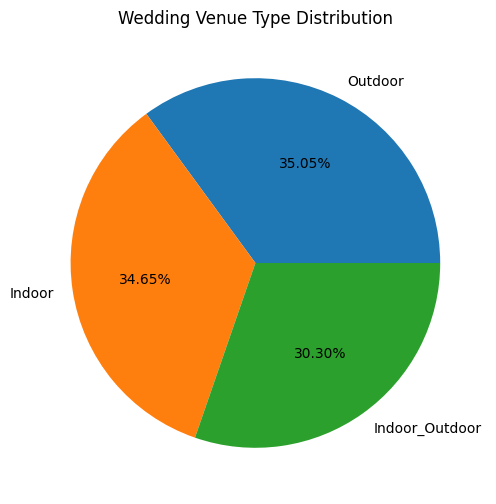

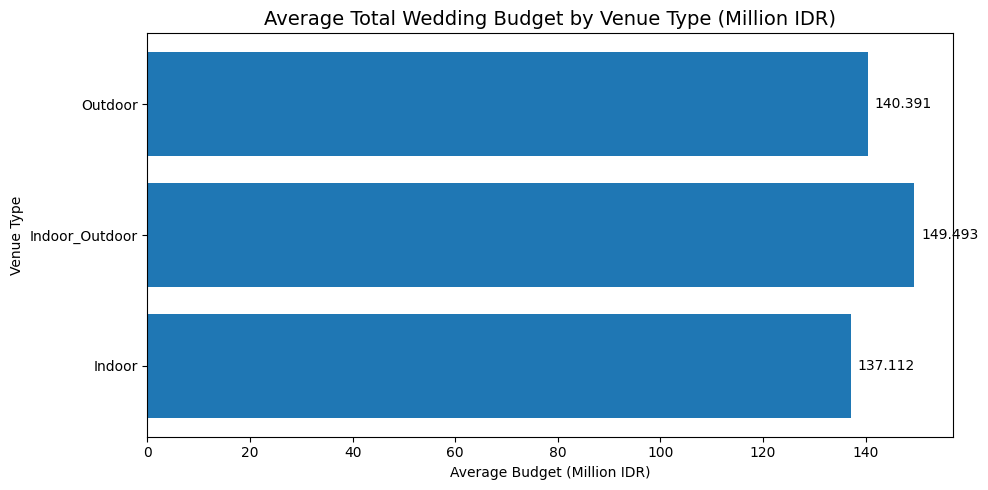

In [ ]:
venue_count = data["tipe_venue"].value_counts().reset_index()
venue_mean = data.groupby("tipe_venue")["Total_biaya_juta"].mean().reset_index()

print(venue_count)
print(venue_mean)

plt.figure(figsize=(6, 6))
plt.pie(venue_count["count"], labels=venue_count["tipe_venue"], autopct="%1.2f%%")
plt.title("Wedding Venue Type Distribution", fontsize=12)
plt.show()

plt.figure(figsize=(10, 5))
bars_venue = plt.barh(venue_mean["tipe_venue"], venue_mean["Total_biaya_juta"])
plt.bar_label(bars_venue, padding=5)
plt.title("Average Total Wedding Budget by Venue Type (Million IDR)", fontsize=14)
plt.xlabel("Average Budget (Million IDR)")
plt.ylabel("Venue Type")
plt.tight_layout()
plt.show()

## Exploratory Data Analysis & Key Insights

### A. Venue Type Popularity & Average Expenditure
Evaluating venue distribution and average total expenditure across the 2,000 events revealed balanced market adoption with distinct budget tiers:
* **Outdoor:** The most frequently selected venue type with 701 events (**35.05%**), recording an average total budget of **Rp 140.39 million**.
* **Indoor:** Ranked second in volume with 693 events (**34.65%**), offering the lowest average budget at **Rp 137.11 million**.
* **Indoor_Outdoor:** Accounted for 606 events (**30.30%**), yet commanded the highest average total budget at **Rp 149.49 million** due to dual-space setup and weather-contingency requirements.

Rata-rata Total Biaya (Juta Rp):
  level_menu_catering  Total_biaya_juta
0            Ekonomis        103.151030
1             Premium        191.776306
2            Standard        136.680368

Rata-rata Biaya per Tamu (Ribu Rp):
  level_menu_catering  Biaya_per_tamu_ribu
0            Ekonomis           286.074284
1             Premium           448.627795
2            Standard           342.186915


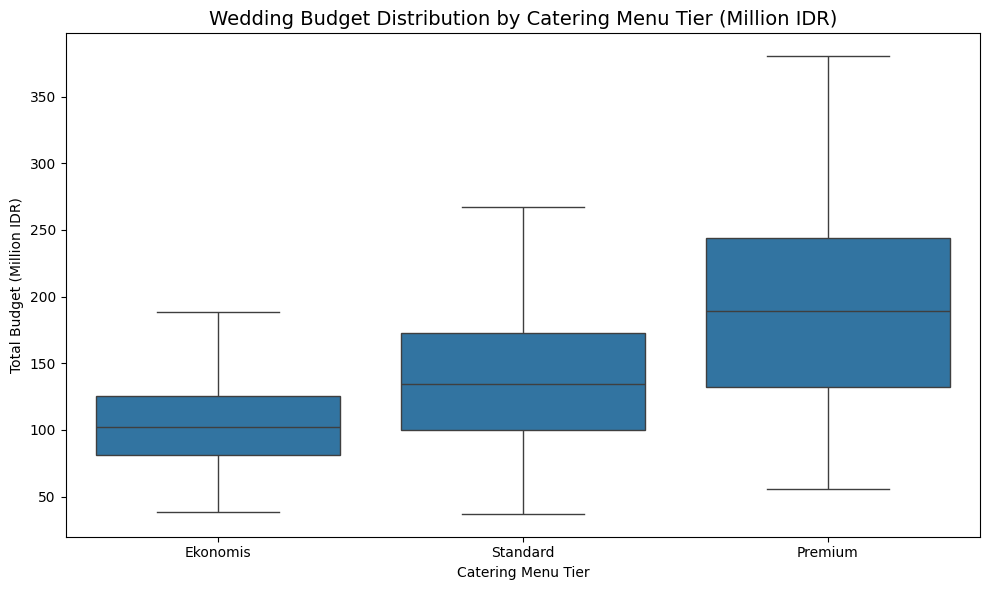

In [ ]:
catering_mean = data.groupby("level_menu_catering")["Total_biaya_juta"].mean().reset_index()
catering_tamu = data.groupby("level_menu_catering")["Biaya_per_tamu_ribu"].mean().reset_index()

print("Rata-rata Total Biaya (Juta Rp):")
print(catering_mean)
print("\nRata-rata Biaya per Tamu (Ribu Rp):")
print(catering_tamu)

plt.figure(figsize=(10, 6))
sns.boxplot(x="level_menu_catering", y="Total_biaya_juta", data=data)
plt.title("Wedding Budget Distribution by Catering Menu Tier (Million IDR)", fontsize=14)
plt.xlabel("Catering Menu Tier")
plt.ylabel("Total Budget (Million IDR)")
plt.tight_layout()
plt.show()

### B. Catering Tier Impact on Total Budget & Cost per Guest
Analyzing total expenditure and per-guest rates across catering tiers identified catering as the single strongest cost driver:
* **Premium Catering:** Recorded the highest average budget at **Rp 191.78 million** (**Rp 448.63 thousand** per guest)—representing an **85.9% cost increase** compared to the economical tier.
* **Standard Catering:** The most commonly chosen tier (822 events), averaging **Rp 136.68 million** (**Rp 342.19 thousand** per guest).
* **Ekonomis Catering:** Averaged **Rp 103.15 million** (**Rp 286.07 thousand** per guest), maintaining tight interquartile budget control.

  jenis_dekorasi  count
0         Modern    698
1          Mewah    590
2      Sederhana    409
3    Tradisional    303
  jenis_dekorasi  Total_biaya_juta
0          Mewah        160.235895
1         Modern        139.177031
2      Sederhana        125.882719
3    Tradisional        134.832687


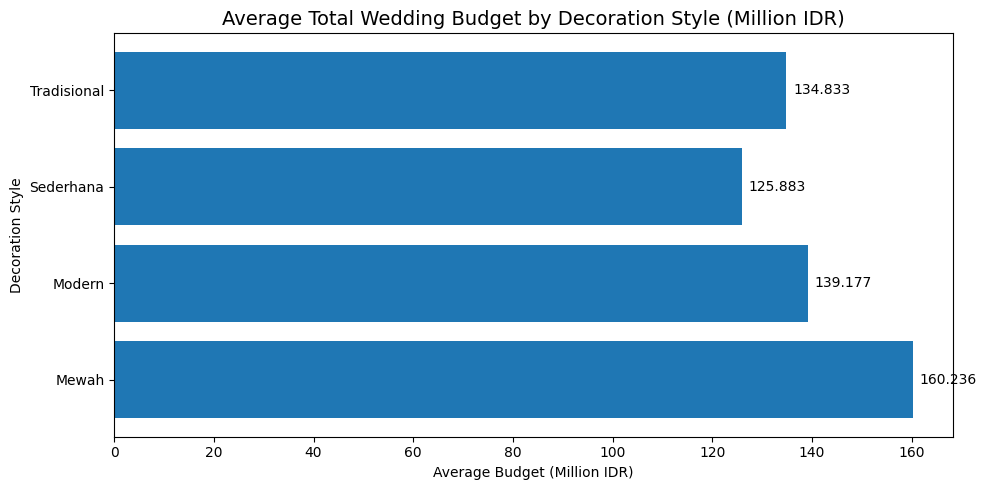

In [ ]:
dekor_count = data["jenis_dekorasi"].value_counts().reset_index()
dekor_mean = data.groupby("jenis_dekorasi")["Total_biaya_juta"].mean().reset_index()

print(dekor_count)
print(dekor_mean)

plt.figure(figsize=(10, 5))
bars_dekor = plt.barh(dekor_mean["jenis_dekorasi"], dekor_mean["Total_biaya_juta"])
plt.bar_label(bars_dekor, padding=5)
plt.title("Average Total Wedding Budget by Decoration Style (Million IDR)", fontsize=14)
plt.xlabel("Average Budget (Million IDR)")
plt.ylabel("Decoration Style")
plt.tight_layout()
plt.show()

### C. Decoration Style Cost Comparison
Comparing average wedding expenditure across decoration themes highlighted clear aesthetic pricing tiers:
* **Mewah (Luxury):** Commanded the highest average budget at **Rp 160.24 million** across 590 events.
* **Modern:** Ranked as the most popular aesthetic (698 events) with a balanced mid-range average budget of **Rp 139.18 million**.
* **Tradisional:** Accounted for 303 events with an average expenditure of **Rp 134.83 million**.
* **Sederhana (Minimalist):** Recorded the lowest average budget at **Rp 125.88 million** across 409 events.

In [ ]:
outdoor = data[data["tipe_venue"] == "Outdoor"]
indoor = data[data["tipe_venue"] == "Indoor"]
in_out = data[data["tipe_venue"] == "Indoor_Outdoor"]

b_outdoor = outdoor.groupby("bulan_pelaksanaan")["Total_biaya_juta"].mean().reset_index()
b_indoor = indoor.groupby("bulan_pelaksanaan")["Total_biaya_juta"].mean().reset_index()
b_inout = in_out.groupby("bulan_pelaksanaan")["Total_biaya_juta"].mean().reset_index()

final_bulan = b_outdoor.merge(b_indoor, on="bulan_pelaksanaan")
final_bulan = final_bulan.merge(b_inout, on="bulan_pelaksanaan")
final_bulan.columns = ["Bulan", "Outdoor", "Indoor", "Indoor_Outdoor"]
print(final_bulan)

fig = px.line(final_bulan, x="Bulan", y=["Outdoor", "Indoor", "Indoor_Outdoor"],
              title="Monthly Average Wedding Budget by Venue Type (Million IDR)")
fig.show()

    Bulan     Outdoor      Indoor  Indoor_Outdoor
0       1  160.554536  160.156581      179.111302
1       2  126.337216  128.927437      121.670208
2       3  134.556304  130.458454      162.908242
3       4  139.269455  111.826208      140.226673
4       5  147.548226  125.929794      145.980084
5       6  155.976348  149.774581      165.935243
6       7  148.845536  150.352057      148.837122
7       8  146.834587  144.870007      168.842893
8       9  122.792040  129.265452      126.012488
9      10  125.733472  118.821041      136.750073
10     11  122.544381  114.131940      127.534575
11     12  158.192964  170.606166      178.713154


### D. Monthly Seasonal Budget Trends by Venue Type
Tracking monthly average expenditure (`bulan_pelaksanaan` 1 to 12) across venue types revealed strong seasonal pricing cycles:
* **Year-End & New Year Peak (December – January):** Average budgets surged across all venue types in **December** (Indoor: **Rp 170.61M**, Indoor_Outdoor: **Rp 178.71M**, Outdoor: **Rp 158.19M**) and **January** (Indoor_Outdoor: **Rp 179.11M**).
* **Mid-Year Holiday Surge (June – August):** A secondary peak occurred during school and mid-year holidays, pushing average budgets to **Rp 149.39M – Rp 157.27M**.
* **Off-Peak Savings Window (February & September – November):** Events held in **November** (overall average **Rp 121.89M**) and **February** (**Rp 125.74M**) offered up to **25–28% lower total costs** compared to peak December rates.

   level_menu_catering jenis_dekorasi  Total_biaya_juta
0             Ekonomis          Mewah        123.096965
1             Ekonomis         Modern        100.866834
2             Ekonomis      Sederhana         87.534111
3             Ekonomis    Tradisional         97.404659
4              Premium          Mewah        205.931268
5              Premium         Modern        184.892292
6              Premium      Sederhana        187.076662
7              Premium    Tradisional        186.433874
8             Standard          Mewah        153.732236
9             Standard         Modern        136.108682
10            Standard      Sederhana        121.643193
11            Standard    Tradisional        122.290638


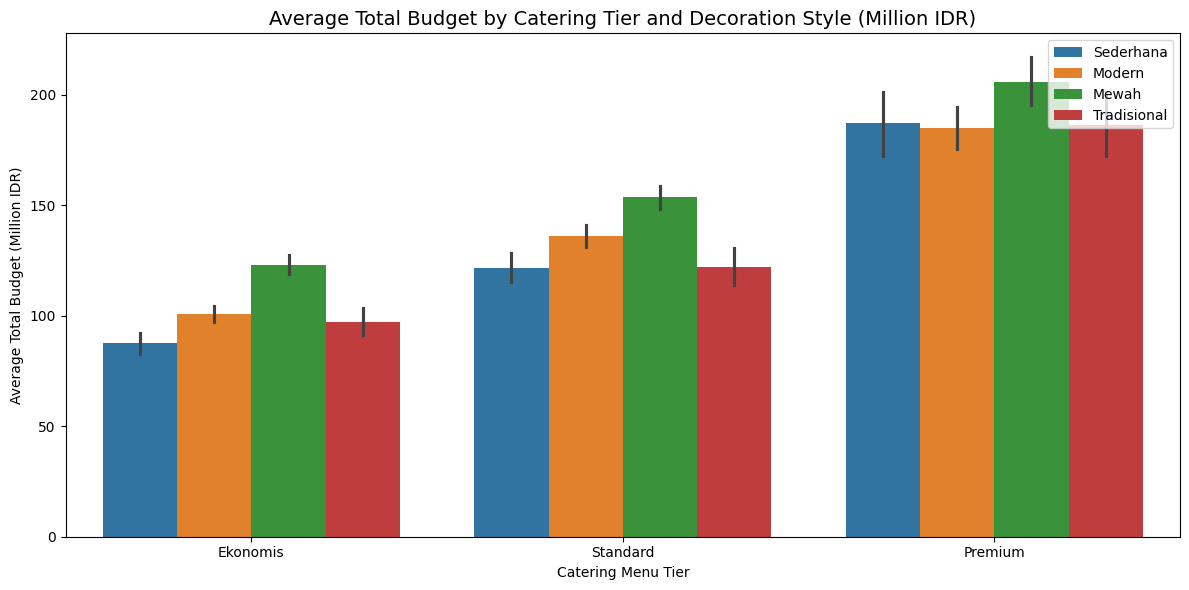

In [ ]:
combo = data.groupby(["level_menu_catering", "jenis_dekorasi"])["Total_biaya_juta"].mean().reset_index()
print(combo)

plt.figure(figsize=(12, 6))
sns.barplot(x="level_menu_catering", y="Total_biaya_juta", hue="jenis_dekorasi", data=data)
plt.title("Average Total Budget by Catering Tier and Decoration Style (Million IDR)", fontsize=14)
plt.xlabel("Catering Menu Tier")
plt.ylabel("Average Total Budget (Million IDR)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

### E. Combined Impact of Catering Tier & Decoration Style
Cross-analyzing catering menu levels with decoration themes demonstrated how package combinations drive overall budget variance:
* **Highest-Yield Package:** Combining **Premium Catering + Mewah Decoration** generated the highest average budget at **Rp 205.93 million**.
* **Entry-Level Package:** Combining **Ekonomis Catering + Sederhana Decoration** averaged **Rp 87.53 million**—a **Rp 118.40 million** difference from the top-tier combination.
* **Mid-Tier Sweet Spot:** Pairing **Standard Catering + Modern Decoration** averaged **Rp 136.11 million**, representing the market's core volume segment.

---

## Strategic Business & Planning Recommendations
* **Off-Peak Promotional Bundling (Feb & Sep–Nov):** Wedding organizers and venues should offer early-bird discounts or complimentary decoration upgrades during low-demand months (February and September–November) to stabilize occupancy when average budgets drop by ~25%.
* **Dynamic Peak-Season Pricing (Dec–Jan & Jun–Aug):** Capitalize on peak holiday demand by introducing minimum guest thresholds and premium weekend surcharges for high-demand *Indoor_Outdoor* venues.
* **Tiered Package Cross-Selling:** Encourage clients selecting *Standard* catering to upgrade to *Modern* or *Mewah* decoration bundles, as decoration upgrades add ~Rp 14–32 million in revenue without proportionally increasing catering logistics.